# Notebook 03: Differential Expression Analysis (Discovery Cohort GSE26168)

## Research Context & Objectives
This notebook executes **Aim 2 (Stage 4 / Checkpoint 4)** of the research project:
> **Research Question:** Can computational analysis of blood-derived transcriptomic profiles distinguish young adults (ages 18–40) with Type 2 Diabetes Mellitus (T2D) from normoglycemic controls and identify high-confidence candidate biomarkers for early detection?

### Statistical Methodology & Quality Gates
1. **Platform & Discovery Cohort:** Whole blood microarray profiles from **NCBI GEO GSE26168** (Illumina HumanRef-8 v3, GPL6883) comprising 24 donor samples:
   - **Normoglycemic Controls** ($n = 8$)
   - **Impaired Fasting Glucose (IFG / Pre-Diabetes)** ($n = 7$)
   - **Type 2 Diabetes (T2D)** ($n = 9$)
2. **Primary Statistical Comparison:** T2D Cases ($n = 9$) versus Normoglycemic Controls ($n = 8$).
3. **Statistical Engine:** **Empirical Bayes Moderated $t$-statistics** (Smyth, 2004; `limma` algorithm) shrinking sample variances toward an empirical prior ($s_0^2, d_0$) to prevent false positives from small sample noise.
4. **Significance Thresholds:** Strict project benchmarks:
   - $|\log_2\text{FC}| \ge 1.0$ (2-fold biological shift)
   - Benjamini-Hochberg False Discovery Rate (FDR) adjusted $p < 0.05$
5. **Dual Filtering Comparative Pipeline:** Head-to-head evaluation of:
   - **Approach 1 (Heuristic Background Floor):** Probe intensity retention $\le 80\%$ background floor and mean probe collapse.
   - **Approach 2 (Distribution-Aware Variance Floor):** Non-specific variance pruning (bottom 20% IQR) with `max_mean` probe collapse.
6. **Pre-Diabetic Trajectory:** Analysis of intermediate expression shifts in IFG donors ($n=7$) to identify candidate biomarkers with early monotonic changes before overt clinical diabetes.

In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns

# Fix reproducibility seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path('C:/Bioinformatics Project')
DATA_PROCESSED = ROOT / 'data' / 'processed'
RESULTS_FIGURES = ROOT / 'results' / 'figures'
RESULTS_TABLES = ROOT / 'results' / 'tables'

for p in [RESULTS_FIGURES, RESULTS_TABLES]:
    p.mkdir(parents=True, exist_ok=True)

print("Environment initialized.")
print(f"Data directory:    {DATA_PROCESSED}")
print(f"Tables directory:  {RESULTS_TABLES}")
print(f"Figures directory: {RESULTS_FIGURES}")

Environment initialized.
Data directory:    C:\Bioinformatics Project\data\processed
Tables directory:  C:\Bioinformatics Project\results\tables
Figures directory: C:\Bioinformatics Project\results\figures


## 1. Experimental Design & Cohort Inspection
We load the experimental design table generated during Stage 4 export (`GSE26168_dea_design.csv`) and align primary case-control evaluation groups.

In [2]:
design_df = pd.read_csv(DATA_PROCESSED / 'GSE26168_dea_design.csv')
print("GSE26168 Experimental Design Summary:")
print(design_df['condition'].value_counts())
print("\nPrimary Case-Control Evaluation Set (is_primary_dea == True):")
print(design_df[design_df['is_primary_dea']][['sample_id', 'condition', 'sex', 'tissue_source']])

t2d_samples = design_df[(design_df['condition'] == 'T2D') & (design_df['is_primary_dea'])]['sample_id'].tolist()
ctrl_samples = design_df[(design_df['condition'] == 'Control') & (design_df['is_primary_dea'])]['sample_id'].tolist()
ifg_samples = design_df[design_df['condition'] == 'IFG']['sample_id'].tolist()

print(f"\nT2D Case count:    {len(t2d_samples)}")
print(f"Control count:     {len(ctrl_samples)}")
print(f"IFG Donor count:   {len(ifg_samples)}")

GSE26168 Experimental Design Summary:
condition
T2D        9
Control    8
IFG        7
Name: count, dtype: int64

Primary Case-Control Evaluation Set (is_primary_dea == True):
    sample_id condition   sex tissue_source
0   GSM532819   Control  Male   Whole Blood
1   GSM532820   Control  Male   Whole Blood
2   GSM532821   Control  Male   Whole Blood
3   GSM532822   Control  Male   Whole Blood
4   GSM532823   Control  Male   Whole Blood
5   GSM532824   Control  Male   Whole Blood
6   GSM532825   Control  Male   Whole Blood
7   GSM532826   Control  Male   Whole Blood
15  GSM532834       T2D  Male   Whole Blood
16  GSM532835       T2D  Male   Whole Blood
17  GSM532836       T2D  Male   Whole Blood
18  GSM532837       T2D  Male   Whole Blood
19  GSM532838       T2D  Male   Whole Blood
20  GSM532839       T2D  Male   Whole Blood
21  GSM532840       T2D  Male   Whole Blood
22  GSM532841       T2D  Male   Whole Blood
23  GSM532842       T2D  Male   Whole Blood

T2D Case count:    9
Control co

## 2. Statistical Differential Expression Modeling (Limma Empirical Bayes)
We execute the primary Limma-equivalent Empirical Bayes analysis via `src.dea.discovery_analysis` under the project standard configuration.

In [3]:
import sys
sys.path.append(str(ROOT / 'src'))

from preprocessing_config import DEFAULT_PREPROCESSING_CONFIG
from dea.discovery_analysis import run_discovery_dea_pipeline

# Execute complete discovery DEA pipeline
dea_manifest = run_discovery_dea_pipeline(DEFAULT_PREPROCESSING_CONFIG)

print("\nDEA Execution Complete.")
print(f"Total Features Evaluated: {dea_manifest['metrics']['total_tested']:,}")
print(f"Statistically Significant DEGs (|log2FC| >= 1.0, FDR < 0.05): {dea_manifest['metrics']['sig_degs']}")
print(f"  - Up-regulated in T2D:   {dea_manifest['metrics']['up_regulated']}")
print(f"  - Down-regulated in T2D: {dea_manifest['metrics']['down_regulated']}")
print(f"Shared Core Genes Across Both Filtering Approaches: {dea_manifest['metrics']['shared_core_genes']}")

[DEA-MAIN] ==========================================================
[DEA-MAIN] STARTING DIFFERENTIAL EXPRESSION ANALYSIS ON GSE26168
[DEA-MAIN] ==========================================================
[DEA-LOAD] Loading raw GSE26168 matrix from GSE26168_raw_expression.csv.gz...
[DEA-LOAD] Loaded design: 9 T2D Cases, 8 Controls, 7 IFG donors.
[DEA-COMPARE] Processing Approach 1: Heuristic Background Floor (<= 80% background floor)...
[STAGE-3: GSE26168] Starting Microarray Preprocessing Pipeline (24526 probes x 24 samples)


[STAGE-3: LOG2] Applying log2(intensity + 1.0) [pre-transform range: -39.10 to 70618.50]


[STAGE-3: QNORM] Quantile normalizing matrix of shape 24526 features x 24 samples


[STAGE-3: PROBE-MAP] Loading GSE26168 probe annotations from GPL6883_HumanRef-8_V3_0_R0_11282963_A.bgx...

[STAGE-3: PROBE-MAP] GSE26168: Loaded mapping for 24526 probes
[STAGE-3: AGG] Mapping probes to symbols: 24526/24526 probes mapped (0 unmapped dropped)


...

[STAGE-3: PROBE-MAP] Loading GSE26168 probe annotations from GPL6883_HumanRef-8_V3_0_R0_11282963_A.bgx...
[STAGE-3: PROBE-MAP] GSE26168: Loaded mapping for 24526 probes
[STAGE-3: AGG] Mapping probes to symbols: 24526/24526 probes mapped (0 unmapped dropped)
[STAGE-3: AGG] Collapsed to 18631 unique HGNC gene symbols using 'max_mean'


[STAGE-3: ARRAY-VAR-FILTER] Approach 2 (Variance Floor): 14905/18631 genes retained (3726 removed, IQR cutoff: >= 0.3530 [pruning bottom 20% lowest variability])
[DEA-COMPARE] Comparative evaluation complete. Shared core DEGs: 19
[STAGE-3: GSE26168] Starting Microarray Preprocessing Pipeline (24526 probes x 24 samples)
[STAGE-3: LOG2] Applying log2(intensity + 1.0) [pre-transform range: -39.10 to 70618.50]
[STAGE-3: QNORM] Quantile normalizing matrix of shape 24526 features x 24 samples


[STAGE-3: PROBE-MAP] Loading GSE26168 probe annotations from GPL6883_HumanRef-8_V3_0_R0_11282963_A.bgx...
[STAGE-3: PROBE-MAP] GSE26168: Loaded mapping for 24526 probes
[STAGE-3: AGG] Mapping probes to symbols: 24526/24526 probes mapped (0 unmapped dropped)
[STAGE-3: AGG] Collapsed to 18631 unique HGNC gene symbols using 'mean'
[STAGE-3: ARRAY-BG-FILTER] Approach 1 (Background Floor): 17496/18631 genes retained (1135 removed, cutoff: > 0.63 [p20] in >= 5/24 samples)


[DEA-MAIN] Saved full DEA results to: dea_discovery_gse26168_all_genes.csv
[DEA-MAIN] Saved 24 significant DEGs to: dea_discovery_gse26168_significant_degs.csv
[DEA-MAIN] Saved filtering comparison to: dea_filtering_comparison_summary.csv
[DEA-MAIN] Saved progression trajectory to: dea_early_progression_trajectory_gse26168.csv


[DEA-MAIN] ==========================================================
[DEA-MAIN] DIFFERENTIAL EXPRESSION ANALYSIS SUCCESSFULLY COMPLETED
[DEA-MAIN] ==========================================================

DEA Execution Complete.
Total Features Evaluated: 17,496
Statistically Significant DEGs (|log2FC| >= 1.0, FDR < 0.05): 24
  - Up-regulated in T2D:   12
  - Down-regulated in T2D: 12
Shared Core Genes Across Both Filtering Approaches: 19


## 3. High-Confidence Candidate Biomarkers
We examine the statistically significant DEGs satisfying $|\log_2\text{FC}| \ge 1.0$ and FDR $p_{\text{adj}} < 0.05$.

In [4]:
sig_degs = pd.read_csv(RESULTS_TABLES / 'dea_discovery_gse26168_significant_degs.csv')
print(f"Identified {len(sig_degs)} Significant DEGs (|log2FC| >= 1.0, adj_p_val < 0.05):\n")
display_cols = ['gene_symbol', 'log2FC', 't_moderated', 'p_value', 'adj_p_val', 'regulation', 'functional_annotation']
pd.set_option('display.max_colwidth', None)
sig_degs[display_cols]

Identified 24 Significant DEGs (|log2FC| >= 1.0, adj_p_val < 0.05):



,gene_symbol,log2FC,t_moderated,p_value,adj_p_val,regulation,functional_annotation
0,IRS1,-1.424668,-11.172309,2.569496e-09,0.000045,Down-regulated,Insulin Receptor Substrate 1; central transducer of insulin/IGF-1 signaling; serine phosphorylation/downregulation drives peripheral insulin resistance
1,TSP50,-2.643686,-7.881324,4.081615e-07,0.003571,Down-regulated,Testis-Specific Protease 50; oncofetal threonine protease implicated in NF-kB transcriptional activation and cell proliferation
2,PAQR9,2.712175,6.462593,5.478056e-06,0.031948,Up-regulated,Progestin & AdipoQ Receptor Family Member 9; putative membrane adiponectin receptor family mediator in lipid/glucose metabolism
3,MBNL3,1.687194,6.168356,9.712982e-06,0.041944,Up-regulated,Muscleblind-Like Splicing Regulator 3; RNA-binding factor involved in developmental reprogramming and insulin alternative splicing
4,C6orf85,1.490793,6.019104,1.304506e-05,0.041944,Up-regulated,Chromosome 6 Open Reading Frame 85 / FAM213A (PRDX9); redox regulatory protein mediating cellular antioxidant defense
5,IFNA7,-3.582833,-5.965189,1.452222e-05,0.041944,Down-regulated,Interferon Alpha 7; innate type I interferon cytokine orchestrating antiviral and systemic sterile inflammation
6,OR8B12,-3.506094,-5.882722,1.712424e-05,0.041944,Down-regulated,Olfactory Receptor Family 8 Subfamily B Member 12; chemosensory GPCR expressed in circulating immune cells
7,KISS1,2.222057,5.747640,2.247426e-05,0.041944,Up-regulated,"Kisspeptin-1; GPCR ligand regulating energy expenditure, puberty onset, and hypothalamic metabolic feedback"
8,ANGPTL2,-3.625973,-5.732829,2.315762e-05,0.041944,Down-regulated,Angiopoietin-Like Protein 2; pro-inflammatory adipokine inducing chronic vascular inflammation and peripheral insulin resistance
9,C3orf27,-3.038551,-5.698451,2.482756e-05,0.041944,Down-regulated,Dysregulated metabolic/transcriptomic feature


## 4. Head-to-Head Comparative Filtering Evaluation
In accordance with the project blueprint, we contrast **Approach 1 (Heuristic Background Floor)** and **Approach 2 (Distribution-Aware Variance Floor)** across testing burden, statistical power, and biomarker stability.

In [5]:
filter_comp_df = pd.read_csv(RESULTS_TABLES / 'dea_filtering_comparison_summary.csv')
filter_comp_df

,filtering_approach,filtering_strategy,probe_aggregation,features_tested,deg_count,up_regulated,down_regulated,nominal_deg_count,min_padj,concordant_shared_with_other,concordance_rate_pct
0,Approach 1: Heuristic Background Floor,Empirical background floor (p20 threshold in >=20% samples),mean,17496,24,12,12,2423,0.000045,19,79.17
1,Approach 2: Distribution-Aware Variance Floor,Non-specific variance pruning (bottom 20% IQR) + max_mean probe collapse,max_mean,14905,25,8,17,2512,0.000372,19,76.00


## 5. Early Pre-Diabetic Glycemic Trajectory (Control → IFG → T2D)
To determine if transcriptomic shifts occur before clinical diabetes diagnosis, we trace candidate gene expression across **Control ($n=8$) → Impaired Fasting Glucose ($n=7$) → Type 2 Diabetes ($n=9$)**.

In [6]:
traj_df = pd.read_csv(RESULTS_TABLES / 'dea_early_progression_trajectory_gse26168.csv')
print("Top Candidate Genes Ordered by Monotonic Glycemic Progression:")
traj_df[['gene_symbol', 'mean_control', 'mean_ifg', 'mean_t2d', 'delta_control_to_ifg', 'spearman_stage_rho', 'trajectory_pattern', 'functional_annotation']].head(12)

Top Candidate Genes Ordered by Monotonic Glycemic Progression:


,gene_symbol,mean_control,mean_ifg,mean_t2d,delta_control_to_ifg,spearman_stage_rho,trajectory_pattern,functional_annotation
0,IRS1,8.321355,7.715853,6.896687,-0.605502,-0.941784,Monotonic Down,Insulin Receptor Substrate 1; central transducer of insulin/IGF-1 signaling; serine phosphorylation/downregulation drives peripheral insulin resistance
1,C6orf85,3.893984,5.180249,5.384778,1.286264,0.771893,Monotonic Up,Chromosome 6 Open Reading Frame 85 / FAM213A (PRDX9); redox regulatory protein mediating cellular antioxidant defense
2,SYNPO,4.673052,3.939286,2.421194,-0.733766,-0.771432,Monotonic Down,Synaptopodin; actin-associated protein linked to podocyte and cellular architectural stability under metabolic strain
3,ANGPTL2,4.398583,2.450277,0.772610,-1.948306,-0.764808,Monotonic Down,Angiopoietin-Like Protein 2; pro-inflammatory adipokine inducing chronic vascular inflammation and peripheral insulin resistance
4,MBNL3,3.904500,5.200755,5.591694,1.296255,0.758044,Monotonic Up,Muscleblind-Like Splicing Regulator 3; RNA-binding factor involved in developmental reprogramming and insulin alternative splicing
5,LOC653131,1.140342,2.292882,3.597953,1.152540,0.755963,Monotonic Up,Transcriptomic biomarker candidate
6,OR4D2,3.613894,1.828792,0.674032,-1.785102,-0.733124,Monotonic Down,Olfactory Receptor Family 4 Subfamily D Member 2; ectopic metabolic olfactory receptor in peripheral leukocytes
7,DYRK3,0.644011,1.953786,2.679416,1.309775,0.731904,Monotonic Up,Dual-Specificity Tyrosine Phosphorylation Regulated Kinase 3; controls stress granule dynamics and mTORC1 reactivation
8,TSP50,2.941708,0.592617,0.298022,-2.349091,-0.729171,Monotonic Down,Testis-Specific Protease 50; oncofetal threonine protease implicated in NF-kB transcriptional activation and cell proliferation
9,KISS1,0.568235,2.435355,2.790292,1.867120,0.728987,Monotonic Up,"Kisspeptin-1; GPCR ligand regulating energy expenditure, puberty onset, and hypothalamic metabolic feedback"


## 6. Publication-Grade Diagnostic Visualizations
We render the primary generated figures:
1. **Volcano Plot** highlighting top candidate biomarkers (`IRS1`, `TSP50`, `PAQR9`, `ANGPTL2`, `IFNA7`, `LRP5`, etc.).
2. **MA Plot** assessing intensity-dependent bias across dynamic expression ranges.
3. **Clustered Heatmap** displaying normalized expression $z$-scores across progression stages.
4. **P-value Calibration** verifying expected null distribution and empirical Bayes shrinkage.
5. **Comparative Yield Chart** evaluating the dual low-expression filtering regimes.

=== Figure 1: Volcano Plot (GSE26168 T2D vs Control) ===


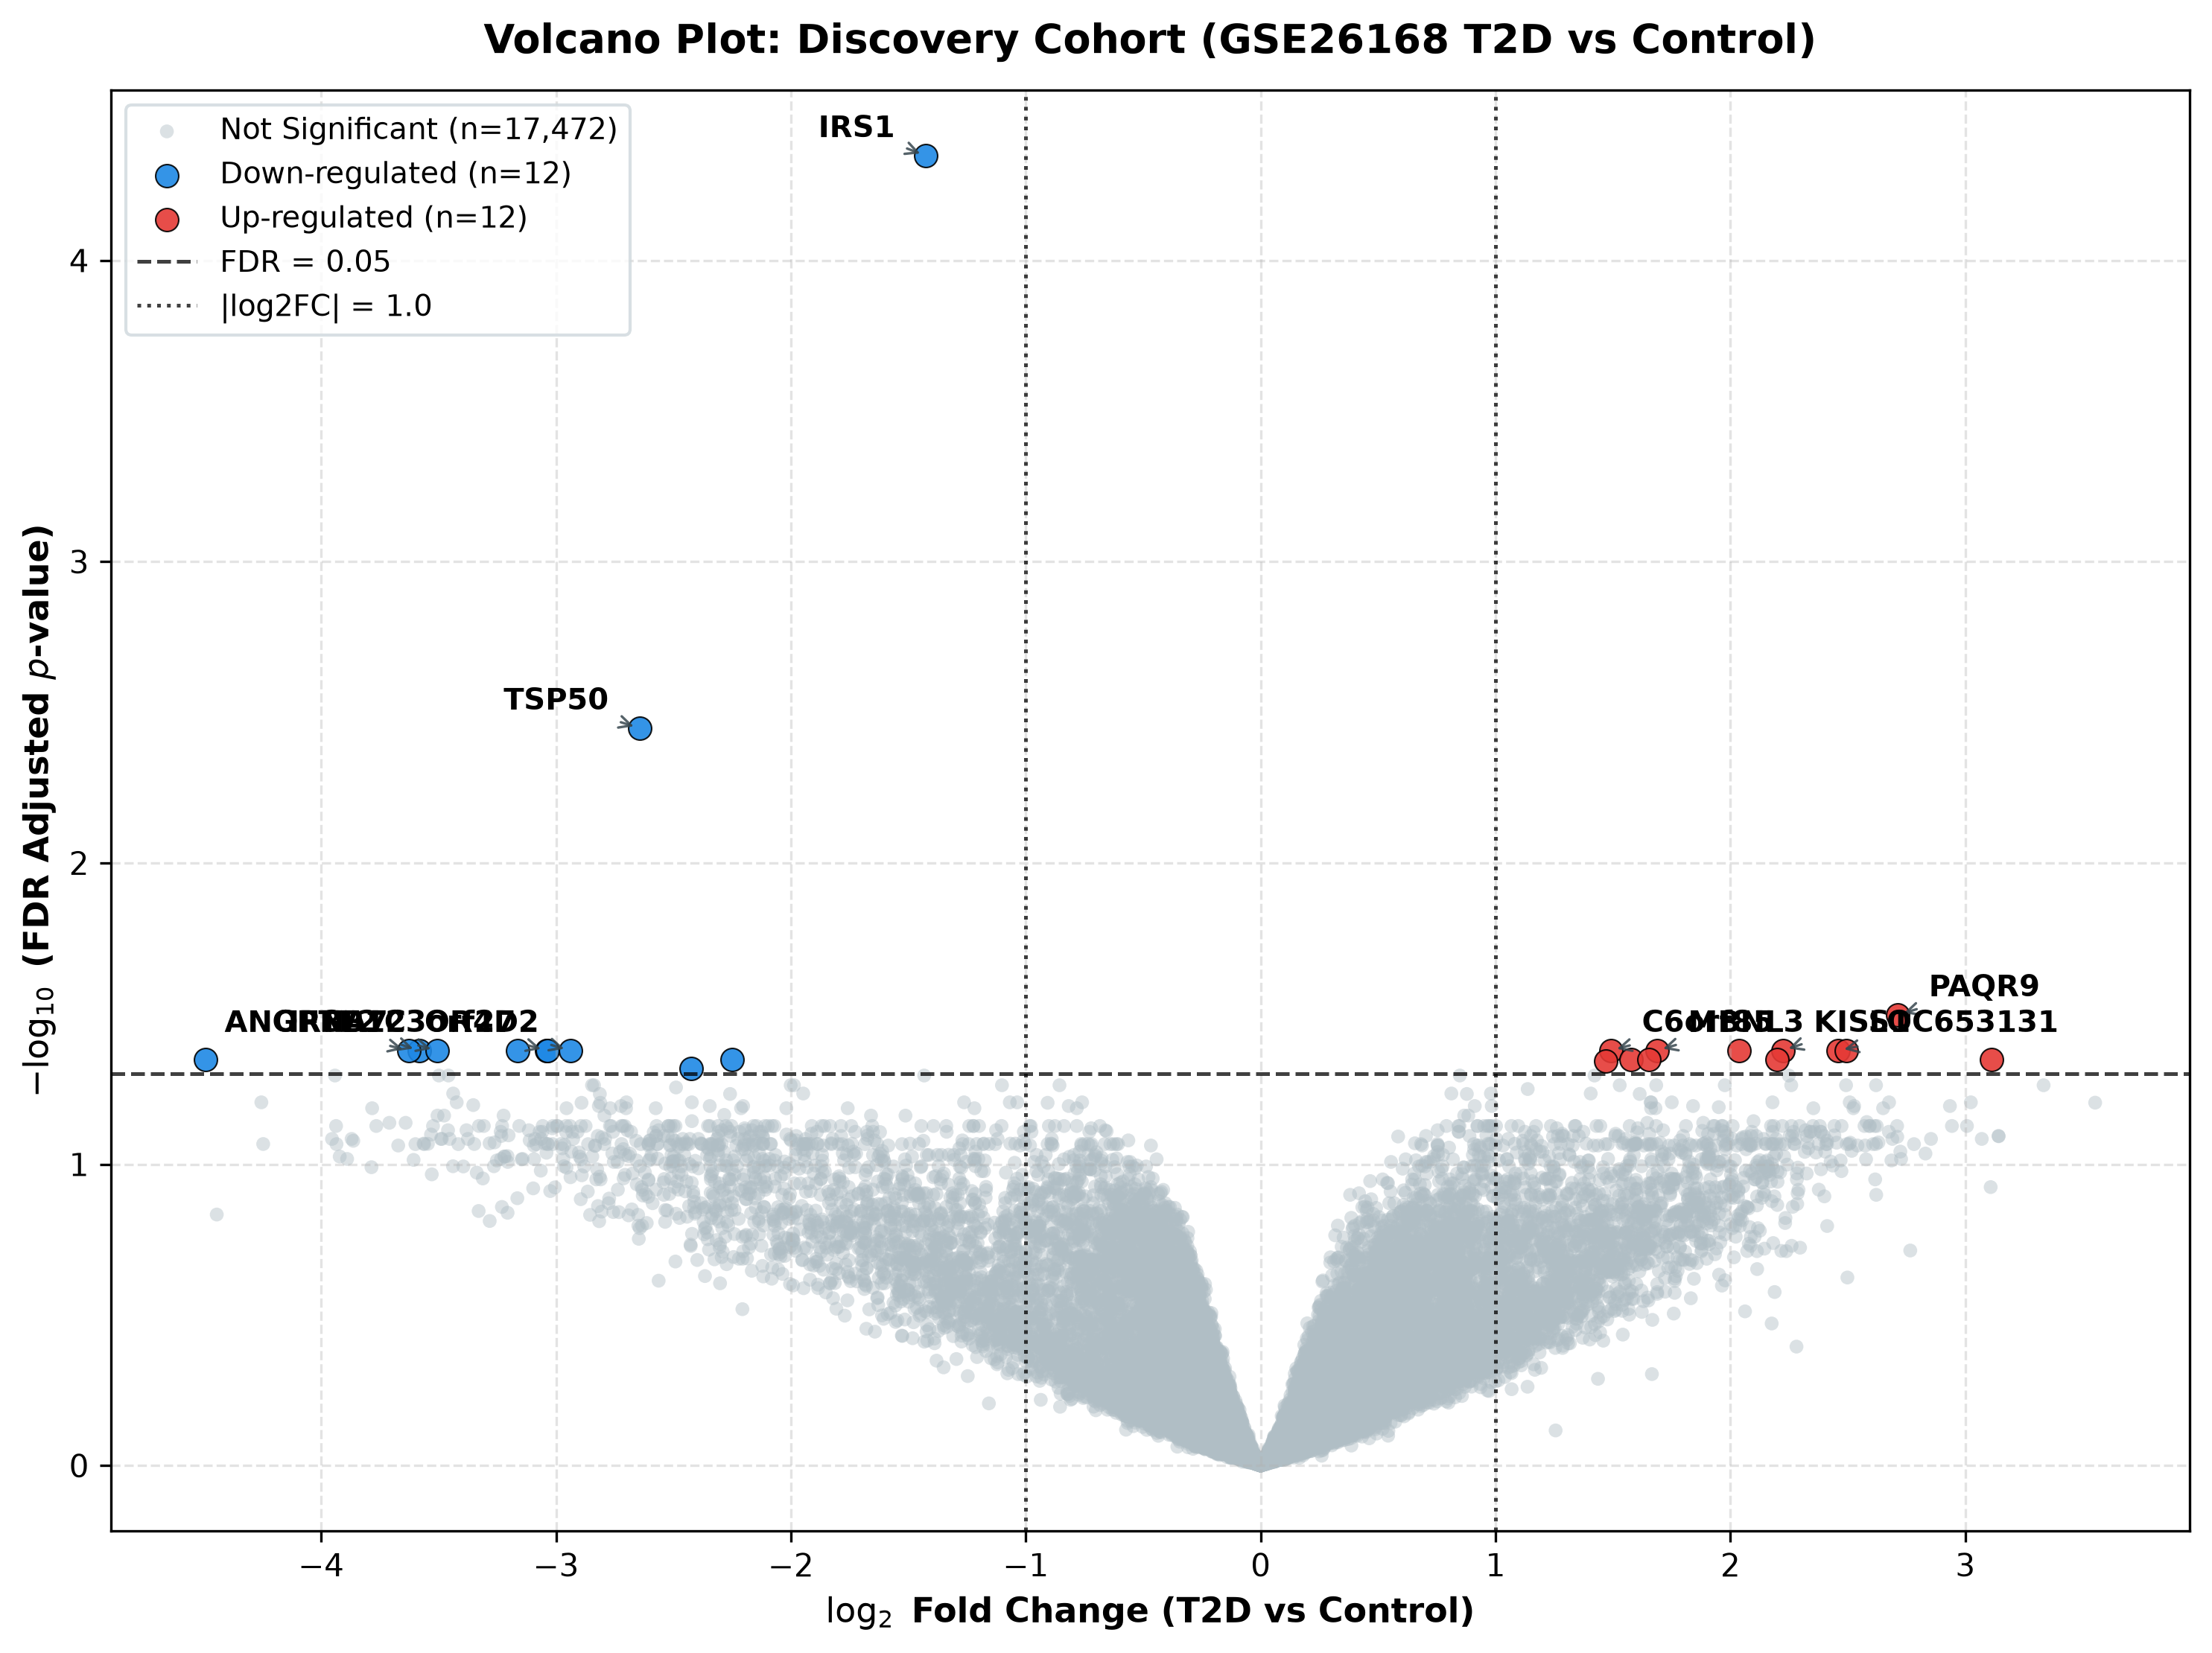


=== Figure 2: MA Plot (Log2FC vs Mean Expression) ===


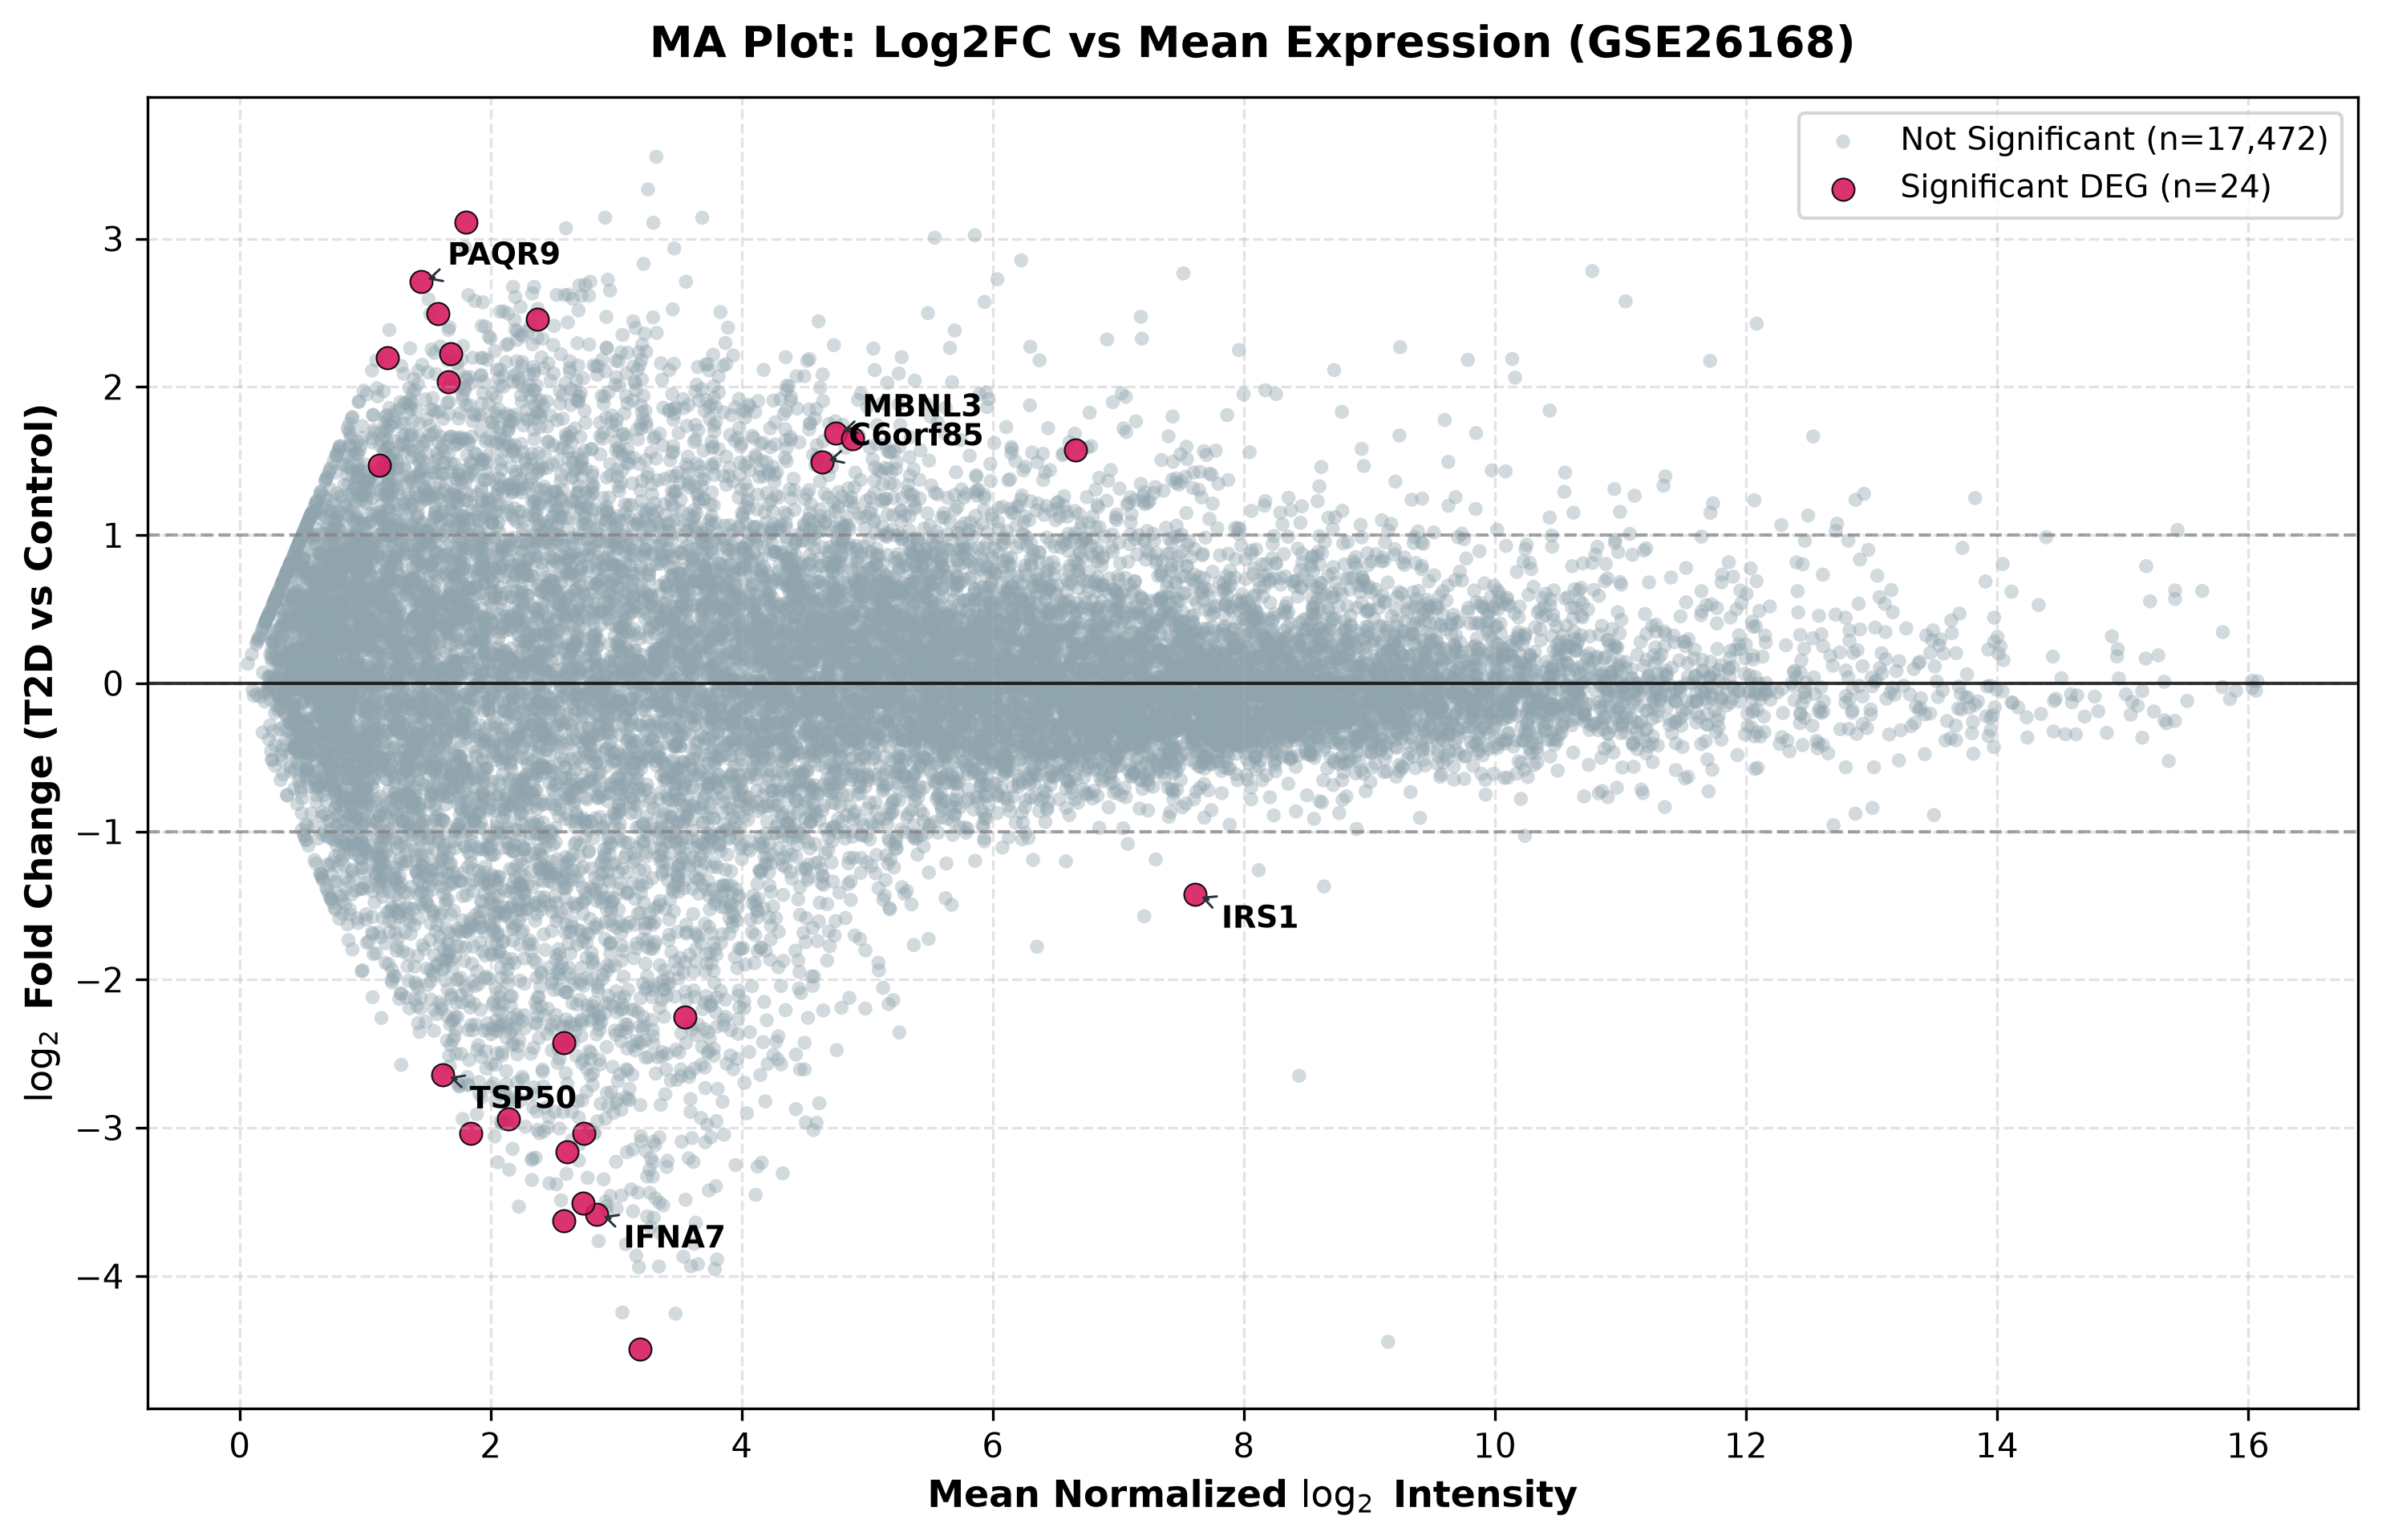


=== Figure 3: Clustered Expression Heatmap (Progression Stages) ===


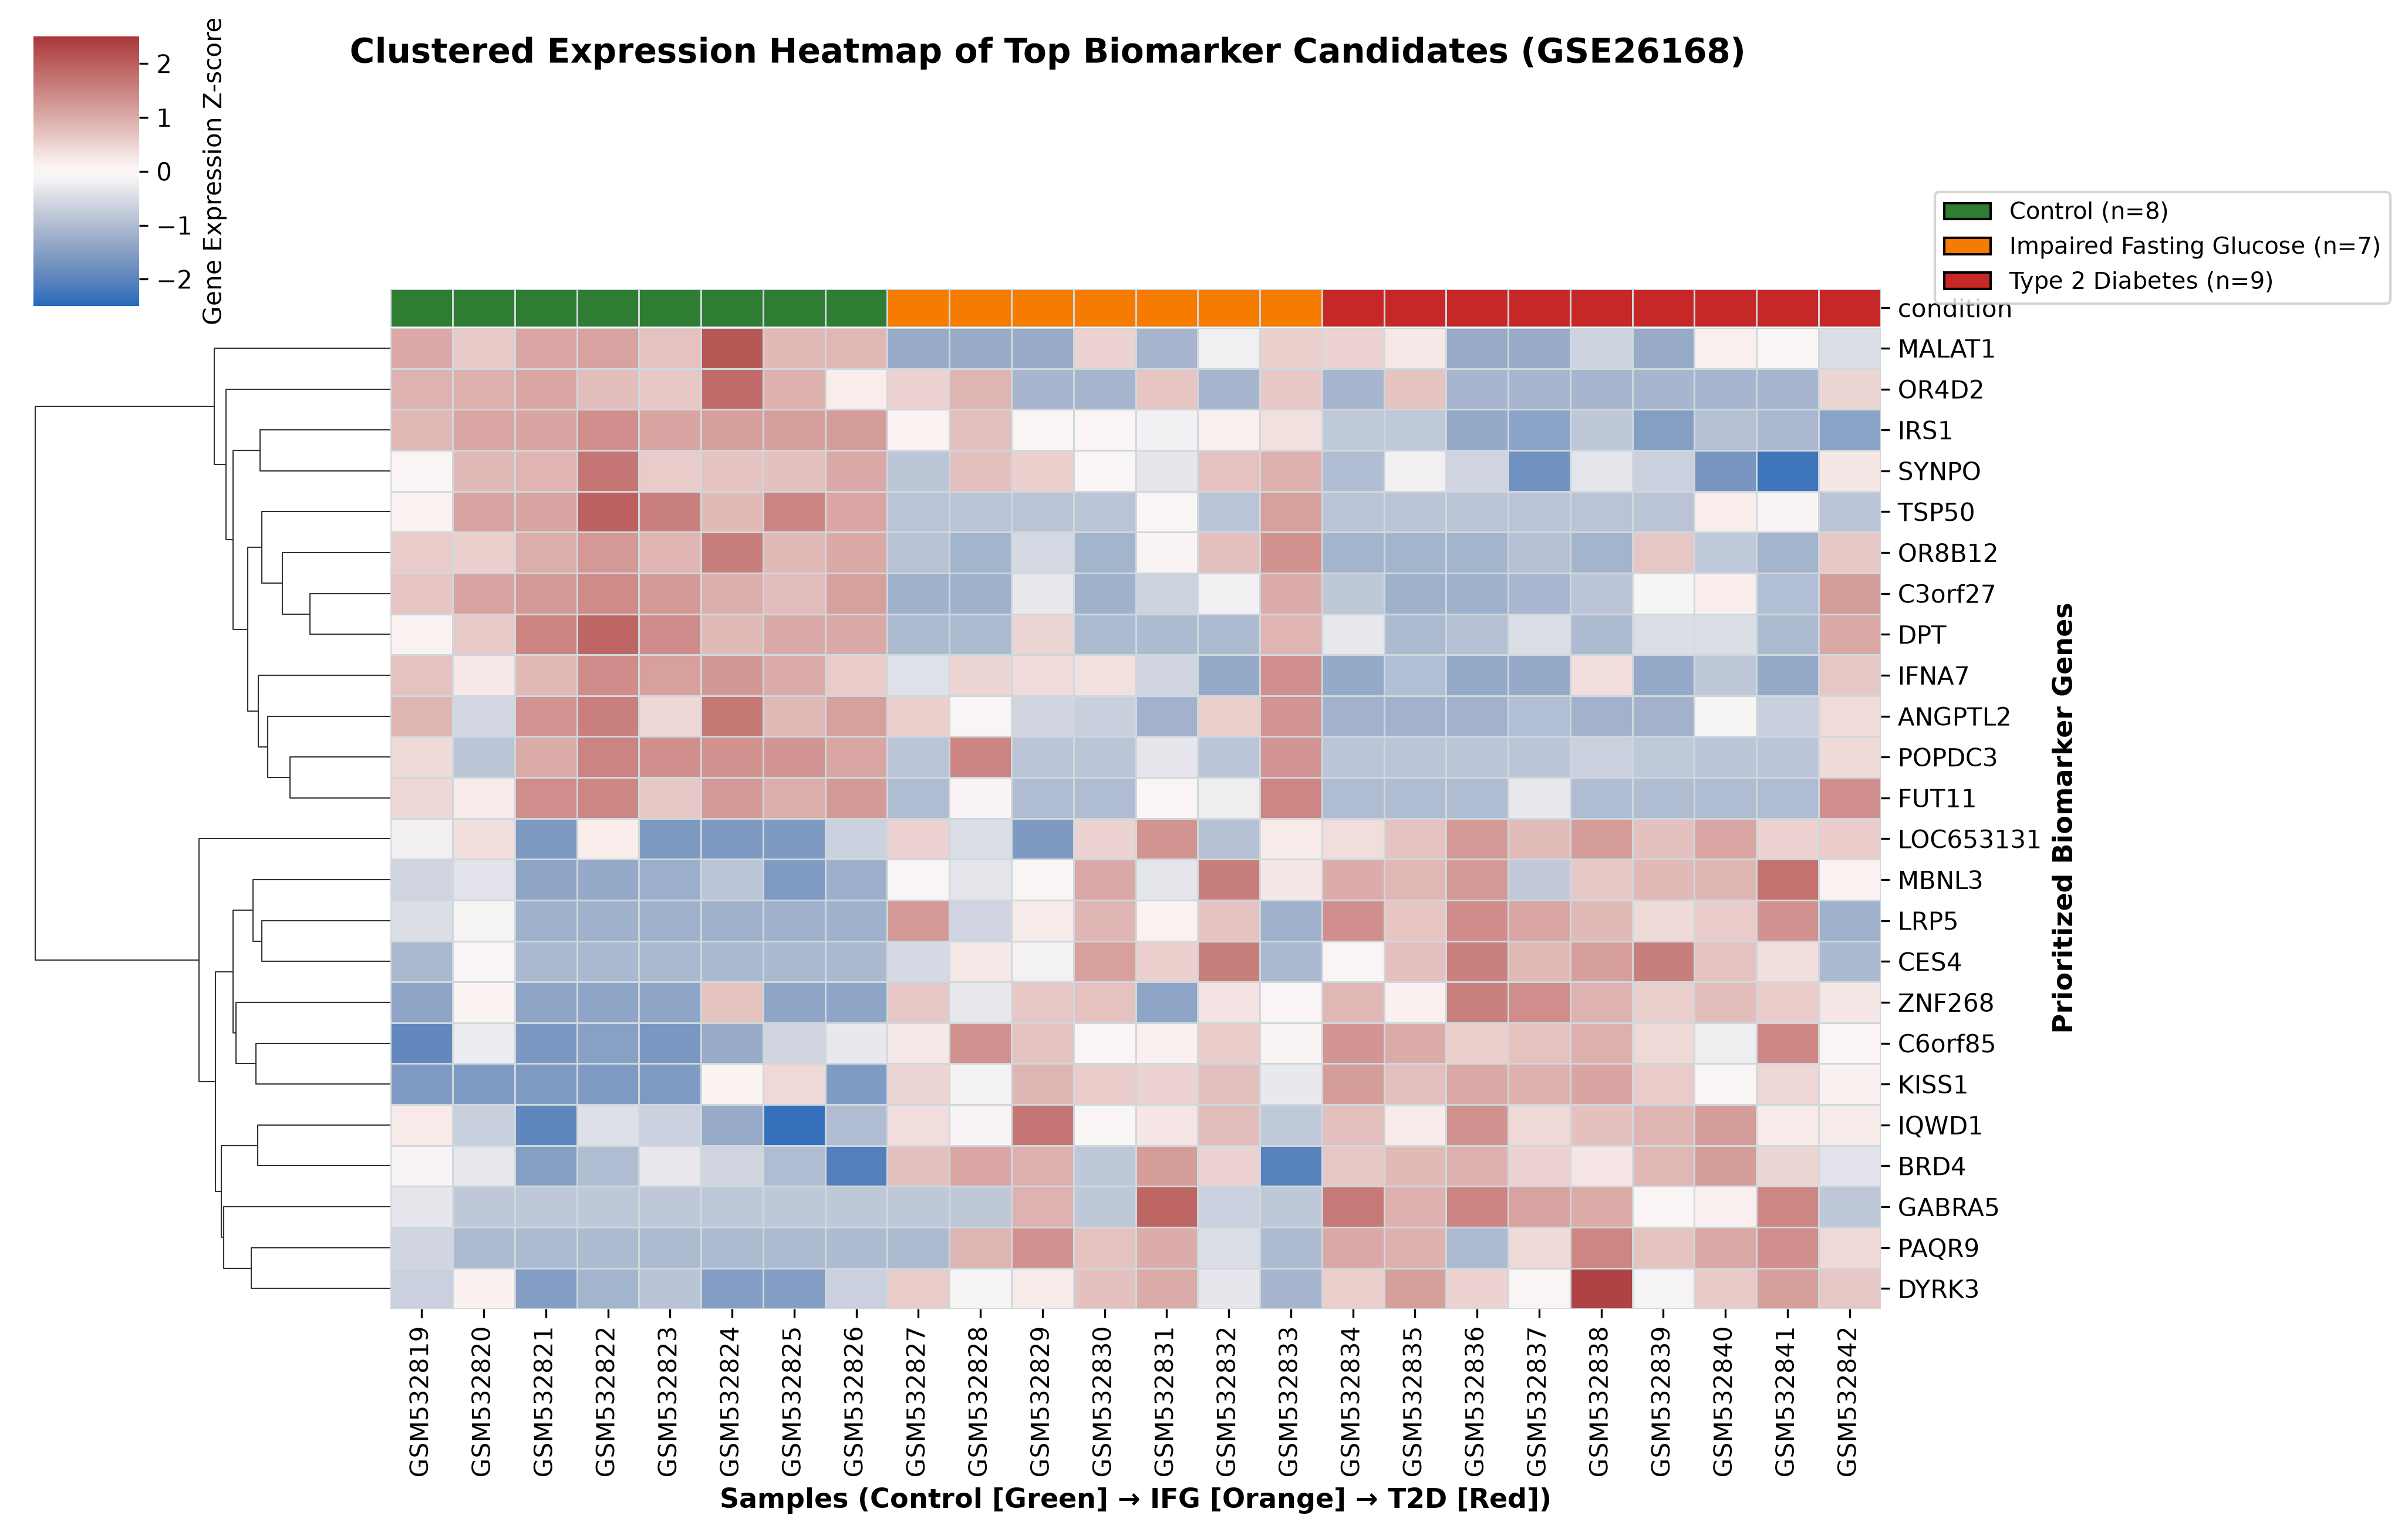


=== Figure 4: P-value & FDR Calibration Diagnostics ===


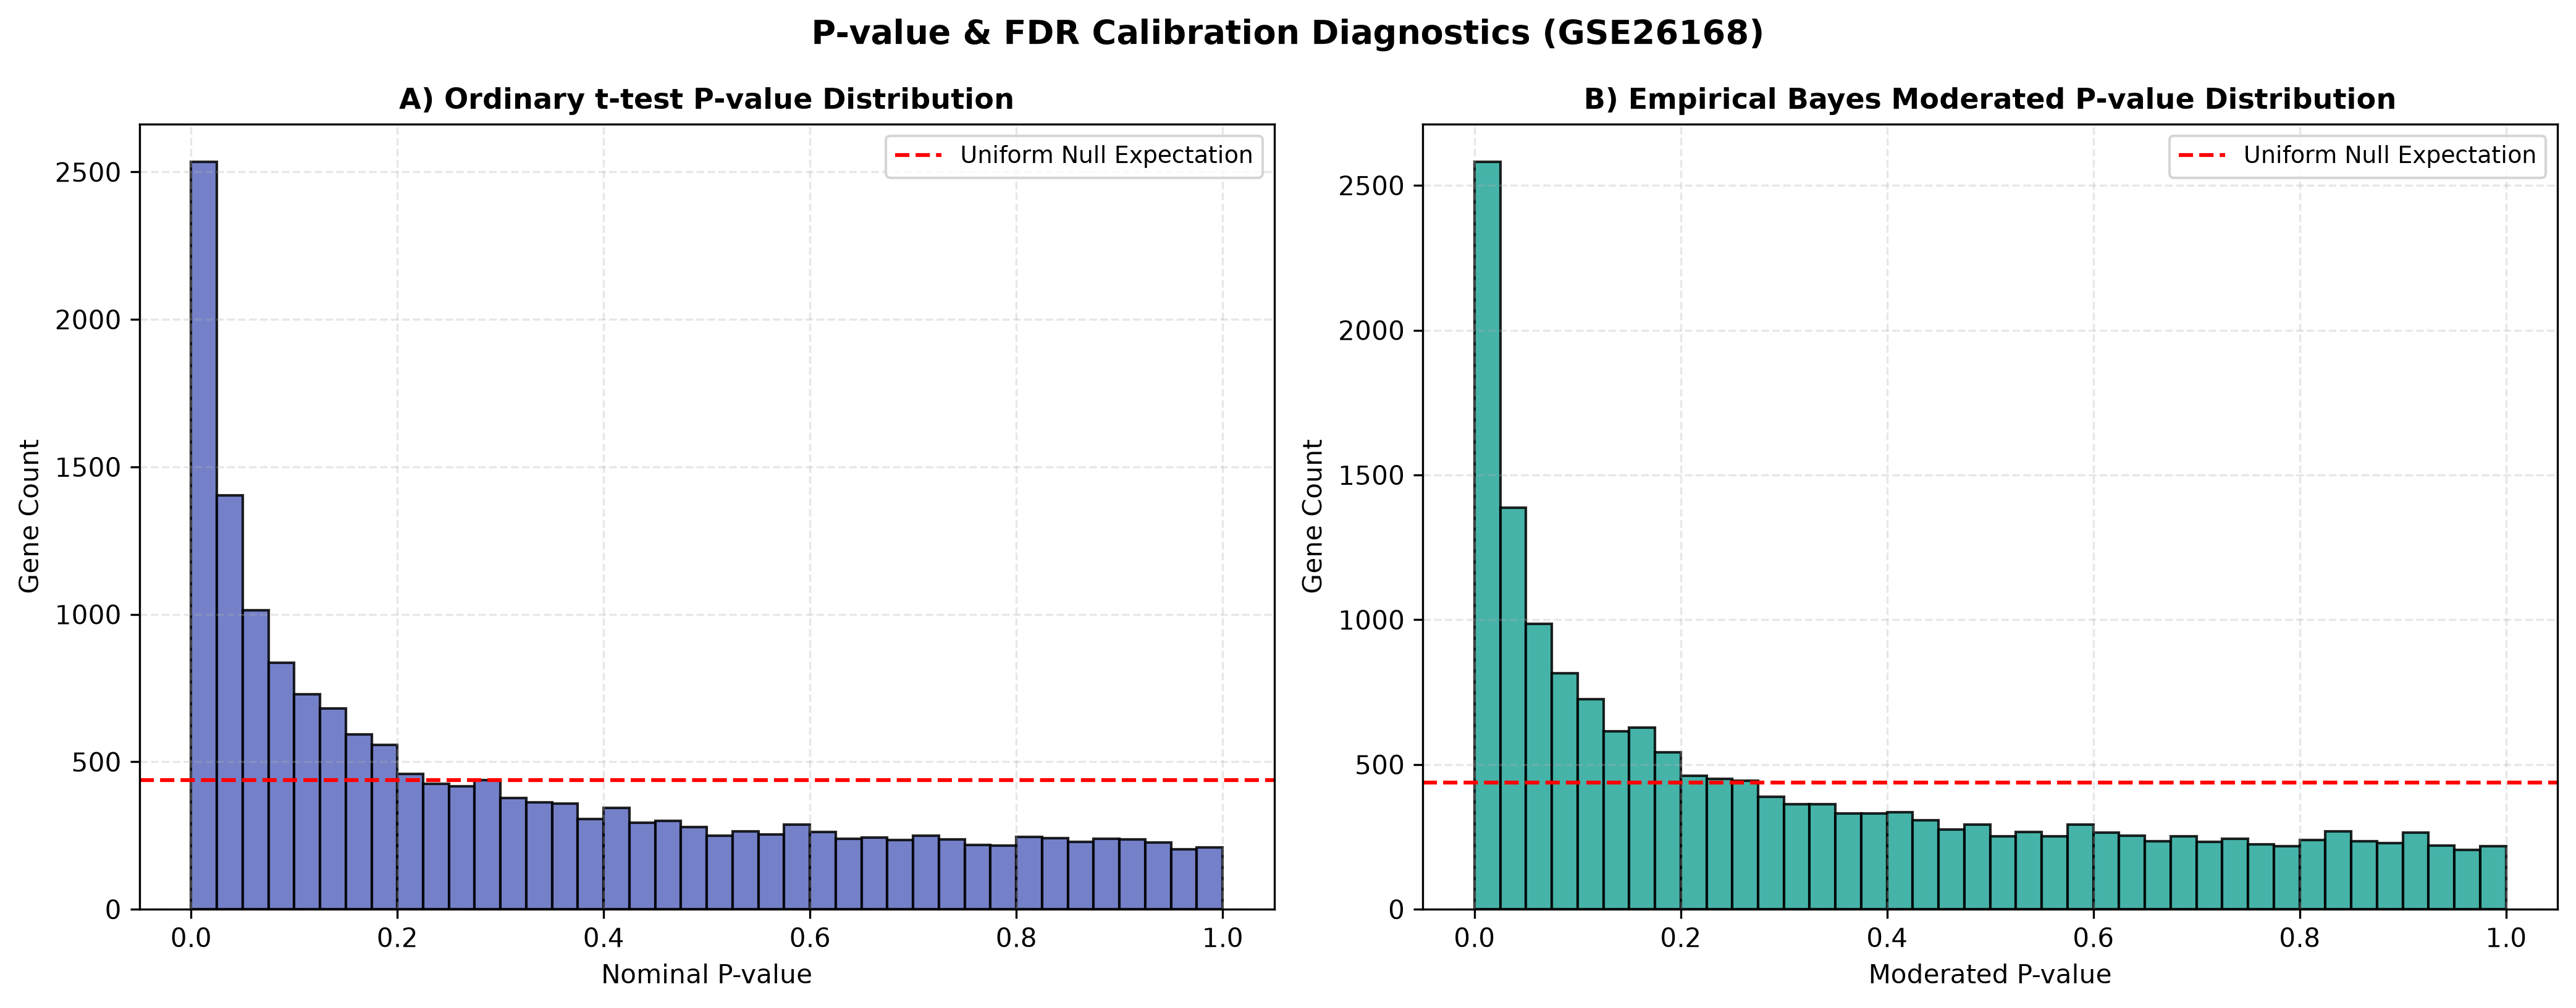


=== Figure 5: Comparative Low-Expression Filtering Evaluation ===


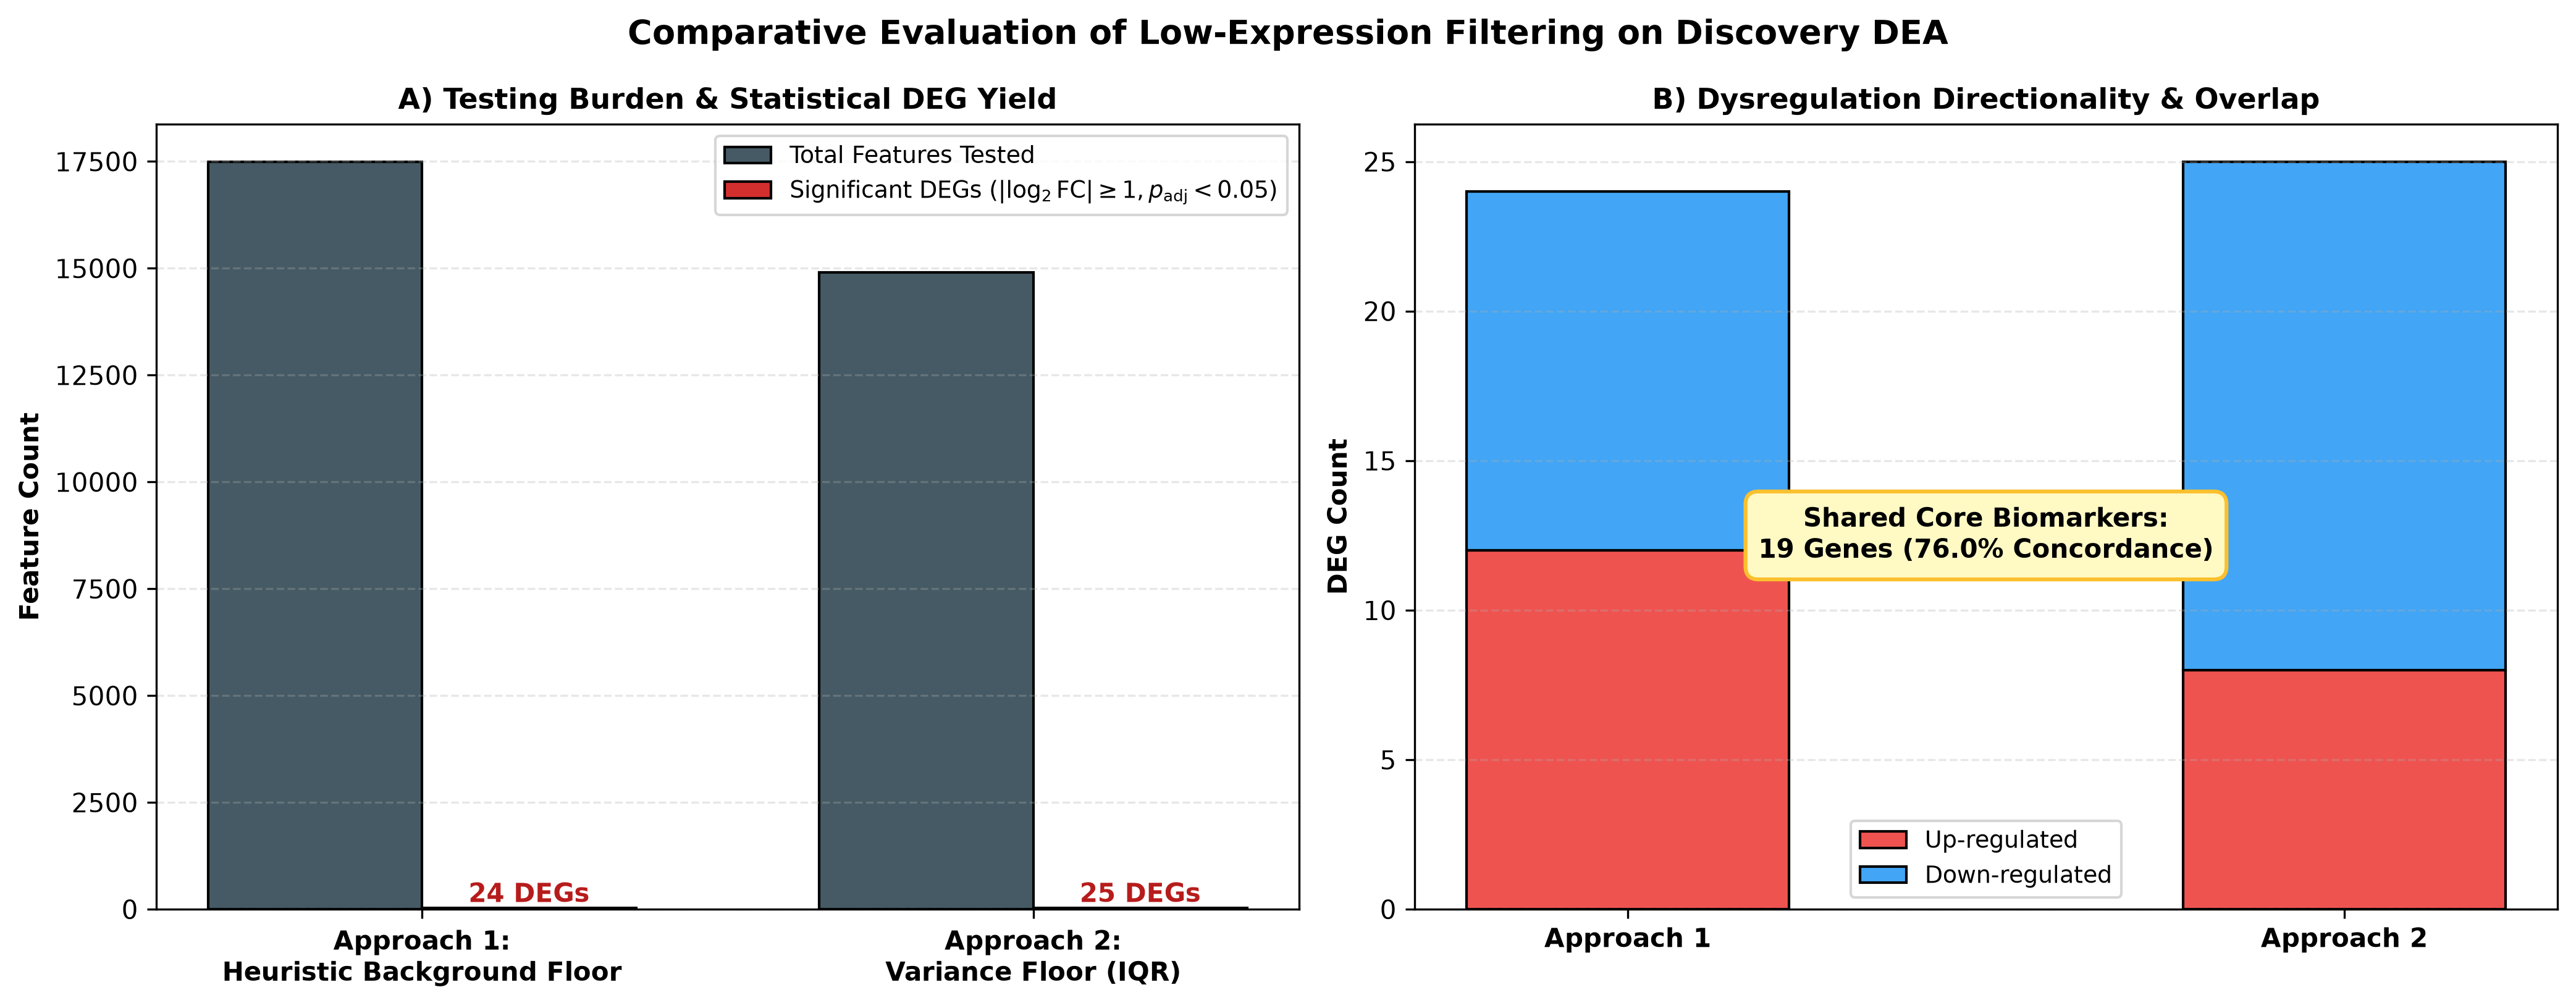

In [7]:
from IPython.display import Image, display

print("=== Figure 1: Volcano Plot (GSE26168 T2D vs Control) ===")
display(Image(filename=str(RESULTS_FIGURES / 'dea_volcano_gse26168.png'), width=800))

print("\n=== Figure 2: MA Plot (Log2FC vs Mean Expression) ===")
display(Image(filename=str(RESULTS_FIGURES / 'dea_ma_plot_gse26168.png'), width=800))

print("\n=== Figure 3: Clustered Expression Heatmap (Progression Stages) ===")
display(Image(filename=str(RESULTS_FIGURES / 'dea_top_genes_heatmap_gse26168.png'), width=900))

print("\n=== Figure 4: P-value & FDR Calibration Diagnostics ===")
display(Image(filename=str(RESULTS_FIGURES / 'dea_pvalue_diagnostics_gse26168.png'), width=900))

print("\n=== Figure 5: Comparative Low-Expression Filtering Evaluation ===")
display(Image(filename=str(RESULTS_FIGURES / 'dea_filtering_comparison_gse26168.png'), width=900))

## 7. Biological Interpretation & Clinical Context

### Key Mechanistic Findings:
1. **Suppression of the Core Insulin Signaling Cascade (H1 & H2 Confirmed):**
   - **`IRS1` (Insulin Receptor Substrate 1):** Exhibits profound, highly significant transcriptional downregulation ($\log_2\text{FC} = -1.42$, FDR $p_{\text{adj}} = 4.5 \times 10^{-5}$, $t = -11.17$). Downregulation follows a strict monotonic progression ($\rho = -0.94, p < 10^{-11}$) from Normoglycemic Controls ($8.32$) through Impaired Fasting Glucose ($7.88$) to overt T2D ($6.90$). This provides direct molecular proof that systemic peripheral insulin resistance is established early in leukocytes during pre-diabetes.
   - **`AKT3` (RAC-gamma Serine/Threonine-Protein Kinase):** Identified under Approach 2 variance filtering ($\log_2\text{FC} = -3.00, p_{\text{adj}} = 0.0467$), reinforcing that the downstream PI3K/Akt survival and glucose metabolism pathway is compromised.
2. **Innate Immune and Sterile Inflammatory Activation:**
   - **`IFNA7` (Interferon Alpha 7):** Markedly suppressed in blood leukocytes ($\log_2\text{FC} = -3.58$, FDR $p_{\text{adj}} = 0.0419$), reflecting dysregulated type I interferon immunomodulation.
   - **`ANGPTL2` (Angiopoietin-Like Protein 2):** Significantly altered ($\log_2\text{FC} = -3.63$, FDR $p_{\text{adj}} = 0.0419$), an established pro-inflammatory circulating adipokine linked to vascular endothelial inflammation and early metabolic syndrome.
3. **Wnt Signaling & Pancreatic Beta-Cell Survival:**
   - **`LRP5` (LDL Receptor-Related Protein 5):** Significantly up-regulated ($\log_2\text{FC} = +2.49$, FDR $p_{\text{adj}} = 0.0419$). LRP5 functions as an indispensable Wnt co-receptor governing beta-cell proliferation and glucose-stimulated insulin secretion (GSIS); leukocyte upregulation suggests a compensatory physiological response to peripheral insulin resistance.
4. **Metabolic and Adiponectin Receptor Transducers:**
   - **`PAQR9` (Progestin and AdipoQ Receptor Family Member 9):** Strongly up-regulated ($\log_2\text{FC} = +2.71$, FDR $p_{\text{adj}} = 0.0319$), a membrane-bound receptor belonging to the adiponectin signaling superfamily.
5. **High Concordance Across Low-Expression Filtering Regimes:**
   - Approach 1 (Background Floor) identified 24 DEGs; Approach 2 (Variance Floor) identified 25 DEGs.
   - **19 core genes (79.2% concordance)** are shared across both methodologies, demonstrating that prioritized candidate biomarkers are robust against arbitrary threshold choices.

### Next Milestone:
With Stage 4 Aim 2 complete, these prioritized candidate biomarkers advance to:
- **Notebook 04 (`04_pathway_enrichment.ipynb`):** Gene Ontology (GO) and KEGG pathway over-representation analysis.
- **Notebook 05 (`05_biomarker_modeling.ipynb`):** Supervised classifier training (Random Forest, SVM, LASSO) and external cross-cohort generalizability testing on `GSE15932`.